The following runs inside the BenchMAX environment.

# Evaluating policies: exact, approximate and against reference opponents

Exploitability measures how much a best-responding opponent could win against a policy profile; it is zero exactly
at a Nash equilibrium. How it can be computed depends on the size and structure of the game. BenchMAX offers four
families of evaluators, selected with `evaluator=` in `load_game()` or `game.evaluate()`:

| Method | Evaluators | Result | Use when |
| ------ | ---------- | ------ | -------- |
| Exact | `matrix`, `nash_conv`, `exp_a_spiel` | exact exploitability | the whole game tree can be traversed |
| Approximate best response | `approximate_exploitability` | estimate from trained best responses | currently two-player zero-sum games too large for exact traversal |
| Perfect solver | `pons` | sampled lower bound from the solver's game value, plus win/draw/loss rates | perfect-information games with a solver, such as Connect Four |
| Search opponent | `mcts` | win/draw/loss rates against a finite-budget search; no exploitability bound | sequential perfect-information games without a solver, or to compare policies a solver beats equally |

This notebook evaluates the same simple policies with each method where it applies.

## Policies

Every evaluator accepts the same batched policy profile. The notebook uses the uniform random policy throughout,
plus a game-specific stronger policy in each section.

In [1]:
def uniform(player, observations, actions, legal_mask):
    return legal_mask / legal_mask.sum(axis=1, keepdims=True)


def exploitability_line(label, results):
    return f"{label:>10}: exploitability {results['exploitability']:.3f}  (NashConv {results['nash_conv']:.3f})"

## 1. Exact exploitability

For small games BenchMAX computes exact best responses by traversing the whole game. Each game has a default exact
evaluator, so `game.evaluate(policy)` needs no extra configuration.

### Rock–Paper–Scissors: `matrix`

A normal-form game is evaluated directly from its payoff matrix. A policy that favours rock is exploited by paper.

In [2]:
import numpy as np

from benchmax import load_game

rps = load_game("rock_paper_scissors")
print("evaluator:", type(rps.evaluator).__name__)


def rock_heavy(player, observations, actions, legal_mask):
    return np.tile([0.5, 0.3, 0.2], (len(observations), 1)) * legal_mask


print(exploitability_line("uniform", rps.evaluate(uniform)))
print(exploitability_line("rock-heavy", rps.evaluate(rock_heavy)))

evaluator: MatrixEvaluator
   uniform: exploitability 0.000  (NashConv 0.000)
rock-heavy: exploitability 0.300  (NashConv 0.600)


### Kuhn Poker: `nash_conv`

Kuhn Poker is a small imperfect-information game, evaluated exactly through OpenSpiel. Tabular CFR, which needs no
neural-training dependencies, converges to an equilibrium within a second.

In [3]:
from benchmax.training import train

kuhn = load_game("kuhn_poker")
print("evaluator:", type(kuhn.evaluator).__name__)

cfr = train(kuhn, "cfr", iterations=1_000, seed=0)
kuhn_policies = {"uniform": uniform, "cfr": cfr}

kuhn_exact = {label: kuhn.evaluate(policy) for label, policy in kuhn_policies.items()}
for label, results in kuhn_exact.items():
    print(exploitability_line(label, results))

evaluator: OpenSpielNashConvEvaluator


   uniform: exploitability 0.458  (NashConv 0.917)
       cfr: exploitability 0.002  (NashConv 0.004)


### Larger imperfect-information games: `exp_a_spiel`

Phantom Tic-Tac-Toe and 3x3 Dark Hex are evaluated exactly by exp-a-spiel's native traversal. This is still exact,
but it takes minutes and several gigabytes of memory per evaluation, so this notebook does not run it; see
[`phantom_tic_tac_toe.ipynb`](phantom_tic_tac_toe.ipynb).

### Connect Four on a tiny board: `nash_conv`

`nash_conv` works for any OpenSpiel game whose tree fits in memory. For Connect Four that means a toy board, such as
2x3 with three in a row. The standard 6x7 board has about 4.5 trillion positions, far beyond exact traversal; it is
evaluated against a perfect solver in section 3.

In [4]:
tiny_connect_four = load_game(
    "openspiel.connect_four", params={"rows": 2, "columns": 3, "x_in_row": 3}, evaluator="nash_conv"
)
print(exploitability_line("uniform", tiny_connect_four.evaluate(uniform)))

   uniform: exploitability 0.083  (NashConv 0.167)


## 2. Approximate best response

`approximate_exploitability` trains a best response (by default with IPPO) against each player's frozen policy and
measures what it wins on fresh episodes. It currently applies to two-player zero-sum games of any size, but the trained
response may be weaker than a true best response, so the result tends to *underestimate* exploitability (apart from sampling noise). It requires the `training` extra.

Kuhn Poker allows a direct comparison with the exact values above. The training budget here is kept small so the
cell runs in about half a minute.

In [5]:
approximate_kuhn = load_game(
    "kuhn_poker",
    evaluator={"name": "approximate_exploitability", "total_frames": 20_000, "episodes": 500, "seed": 0},
)

print("policy     exact   approximate")
for label, policy in kuhn_policies.items():
    approximate = approximate_kuhn.evaluate(policy)
    print(
        f"{label:<9} {kuhn_exact[label]['exploitability']:6.3f}   "
        f"{approximate['approximate_exploitability']:6.3f} ± {approximate['raw_exploitability_standard_error']:.3f}"
    )

policy     exact   approximate


uniform    0.458    0.336 ± 0.052


cfr        0.002    0.000 ± 0.039


The trained responses find most, but not all, of the uniform policy's exploitability, and correctly find nothing
to exploit in the CFR equilibrium. More frames (`total_frames`) and restarts (`restarts`) tighten the estimate.

## 3. Perfect solver

For perfect-information games with a known solver, the `pons` evaluator plays the policy against
[Pascal Pons' Connect Four solver](https://github.com/PascalPons/connect4). The solver knows the value of the game,
so the policy's shortfall from that value is a *lower bound on exploitability*: a best response to the policy can
only do better than the solver. Each seat also reports win, draw and loss rates.

The solver is an external AGPL-3.0 program that BenchMAX does not ship. Install it once per board size, which
downloads its source at a pinned commit and compiles it (a few seconds; needs internet access, `make` and a C++
compiler; the standard board also downloads a 32 MB opening book):

```bash
benchmax setup pons --rows 6 --columns 7
```

The cell below does the same from Python and returns immediately when a board is already installed.

In [6]:
from benchmax.integrations.pons.install import install

for rows, columns in [(6, 7), (4, 5), (5, 6)]:
    install(rows=rows, columns=columns)

### A stronger Connect Four policy

Besides random play, the solver evaluates a hand-written **tactical** policy: it completes its own four in a row
when it can, otherwise blocks the opponent's, otherwise prefers moves near the centre. Connect Four observes the
board as three planes: player 0's discs, player 1's discs and the empty cells.

In [7]:
def completes_line(stones, cell, k=4):
    rows, columns = stones.shape
    row, column = cell
    for step_row, step_column in ((0, 1), (1, 0), (1, 1), (1, -1)):
        length = 1
        for sign in (1, -1):
            r, c = row + sign * step_row, column + sign * step_column
            while 0 <= r < rows and 0 <= c < columns and stones[r, c]:
                length += 1
                r, c = r + sign * step_row, c + sign * step_column
        if length >= k:
            return True
    return False


def tactical_policy(rows, columns):
    def policy(player, observations, actions, legal_mask):
        probabilities = np.zeros(legal_mask.shape)
        for row, (observation, legal) in enumerate(zip(observations, legal_mask)):
            # Row 0 of each plane is the bottom row.
            planes = np.asarray(observation).reshape(3, rows, columns)
            stones, empty = (planes[0], planes[1]), planes[2]
            moves = [action for action, is_legal in zip(actions, legal) if is_legal]
            cells = {column: (int(np.argmax(empty[:, column])), column) for column in moves}
            chosen = [c for c in moves if completes_line(stones[player], cells[c])] or [
                c for c in moves if completes_line(stones[1 - player], cells[c])
            ]
            if chosen:
                weights = np.ones(len(chosen))
            else:
                chosen = moves
                centre = (np.array(empty.shape) - 1) / 2
                weights = np.array([1 / (1 + np.abs(np.array(cells[c]) - centre).sum()) for c in moves])
            probabilities[row, [actions.index(c) for c in chosen]] = weights / weights.sum()
        return probabilities

    return policy


def connect_four_policies(rows, columns):
    return {"random": uniform, "tactical": tactical_policy(rows, columns)}

### The standard board

`connect_four` is the standard 6x7 board, and `pons` is its default evaluator. The standard board is a first-player
win, so every second-player strategy is optimal: `seats=[0]` plays only the first seat. There, a perfect policy
scores 0 and a policy that always loses scores 1.

In [8]:
connect_four = load_game("connect_four", evaluator={"name": "pons", "seats": [0], "episodes": 200})
for label, policy in connect_four_policies(6, 7).items():
    results = connect_four.evaluate(policy)
    print(
        f"{label:>8}: exploitability >= {results['solver_exploitability']:.2f} "
        f"(± {results['solver_exploitability_standard_error']:.2f}), "
        f"wins {results['win_rates'][0]:.0%}, draws {results['draw_rates'][0]:.0%}"
    )

  random: exploitability >= 1.00 (± 0.00), wins 0%, draws 0%


tactical: exploitability >= 1.00 (± 0.00), wins 0%, draws 0%


Both policies lose every game, so on the standard board the solver cannot tell them apart.

### Smaller boards

`openspiel.connect_four` takes other board sizes, each with its own solver build. These smaller boards are draws
under perfect play, so both seats can lose value and both are evaluated.

In [9]:
print("board  policy    value   exploitability >=   first player W/D/L   second player W/D/L")
for rows, columns in [(4, 5), (5, 6)]:
    game = load_game(
        "openspiel.connect_four", params={"rows": rows, "columns": columns},
        evaluator={"name": "pons", "episodes": 200},
    )
    for label, policy in connect_four_policies(rows, columns).items():
        r = game.evaluate(policy)
        seats = [f"{r['win_rates'][s]:4.0%} {r['draw_rates'][s]:4.0%} {r['loss_rates'][s]:4.0%}" for s in (0, 1)]
        bound = f"{r['solver_exploitability']:.2f} ± {r['solver_exploitability_standard_error']:.2f}"
        print(f"{rows}x{columns}    {label:<9} {r['game_value'][0]:+.0f}      {bound:<19} {seats[0]:<20} {seats[1]}")

board  policy    value   exploitability >=   first player W/D/L   second player W/D/L


4x5    random    +0      0.93 ± 0.01           0%   2%  98%         0%  13%  87%


4x5    tactical  +0      0.84 ± 0.02           0%   2%  98%         0%  31%  69%


5x6    random    +0      1.00 ± 0.00           0%   0% 100%         0%   0% 100%


5x6    tactical  +0      0.97 ± 0.01           0%   4%  96%         0%   2%  98%


## 4. Search opponent: MCTS

The `mcts` evaluator plays the policy against OpenSpiel's Monte Carlo tree search. It works for any sequential
perfect-information OpenSpiel game and needs no installation. With a finite search budget MCTS is not perfect, so it
reports only match results: no game value and no exploitability bound. Its strength grows with `max_simulations`,
the number of simulations per move, so a few settings form a *ladder of opponents*.

On the standard board, where the solver beats both policies in every game, the ladder still tells them apart. Both
seats are evaluated.

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SIMULATIONS = [3, 10, 30, 100, 300, 1000]
EPISODES = 200  # per seat and opponent strength


def mcts_ladder(name, policies, **settings):
    ladder = {}
    for label, policy in policies.items():
        for simulations in SIMULATIONS:
            evaluator = {"name": "mcts", "episodes": EPISODES, "opponent": {"max_simulations": simulations}}
            ladder[label, simulations] = load_game(name, evaluator=evaluator, **settings).evaluate(policy)
    return ladder


def plot_ladder(ladder, title):
    labels = list(dict.fromkeys(label for label, _ in ladder))
    styles = {labels[0]: ("#2a78d6", "o", "-"), labels[1]: ("#eb6834", "s", "--")}
    figure, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, layout="constrained")
    for seat, ax in enumerate(axes):
        for label in labels:
            rates = np.array([ladder[label, s]["win_rates"][seat] for s in SIMULATIONS])
            errors = np.sqrt(rates * (1 - rates) / EPISODES)
            color, marker, linestyle = styles[label]
            ax.errorbar(
                SIMULATIONS, rates, yerr=errors, color=color, marker=marker, linestyle=linestyle, linewidth=2,
                markersize=6, capsize=0, elinewidth=1, label=label,
            )
            if seat == 0:
                ax.annotate(label, (SIMULATIONS[0], rates[0]), xytext=(6, 6), textcoords="offset points", fontsize=9)
        ax.axhline(0.5, color="#8a8a85", linewidth=1, linestyle=":")
        ax.set(xscale="log", title=f"Policy as {'first' if seat == 0 else 'second'} player", ylim=(-0.03, 1.03))
        ax.set_xticks(SIMULATIONS, labels=[str(s) for s in SIMULATIONS])
        ax.minorticks_off()
        ax.set_xlabel("MCTS simulations per move (opponent strength)")
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Win rate")
    axes[1].legend(frameon=False)
    figure.suptitle(title)
    plt.show()


def print_ladder(ladder):
    print("policy    simulations   first player W/D/L      second player W/D/L")
    for (label, simulations), r in ladder.items():
        seats = [f"{r['win_rates'][s]:4.0%} {r['draw_rates'][s]:4.0%} {r['loss_rates'][s]:4.0%}" for s in (0, 1)]
        print(f"{label:<9} {simulations:>11}   {seats[0]:<22}  {seats[1]}")

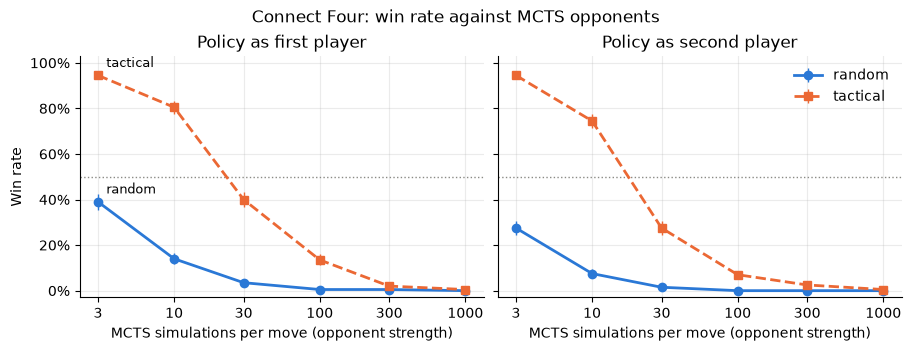

In [11]:
connect_four_ladder = mcts_ladder("connect_four", connect_four_policies(6, 7))
plot_ladder(connect_four_ladder, "Connect Four: win rate against MCTS opponents")

In [12]:
print_ladder(connect_four_ladder)

policy    simulations   first player W/D/L      second player W/D/L
random              3    39%   0%  61%           28%   0%  72%
random             10    14%   0%  86%            8%   0%  92%
random             30     4%   0%  96%            2%   0%  98%
random            100     0%   0% 100%            0%   0% 100%
random            300     0%   0% 100%            0%   0% 100%
random           1000     0%   0% 100%            0%   0% 100%
tactical            3    94%   0%   6%           94%   0%   5%
tactical           10    80%   0%  19%           74%   0%  25%
tactical           30    40%   3%  57%           28%   1%  72%
tactical          100    14%   2%  84%            7%   2%  90%
tactical          300     2%   1%  97%            2%   0%  97%
tactical         1000     0%   0% 100%            0%   1%  98%


The tactical policy beats weak MCTS and loses ground as the opponent searches more; random play loses almost
from the start. As the budget grows, MCTS approaches perfect play and both policies lose almost every game, as they
do against the solver. Where a curve crosses 50% gives a rough strength for the policy in this game, but strength
levels are not comparable across games: 1000 simulations are near-perfect in some games and weak in others. Compare
policies against the same configured opponent.